# Exercise 3 - Generate and test Lagrangian initial conditions

Reference: Lecture 7 notes, Sections 7-8 and Appendix B. Code: `Library/exercise_3.py`.

In [1]:
%matplotlib widget
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../Library")   # folder with the exercise modules

import numpy as np
import matplotlib.pyplot as plt

import exercise_1 as ex1   # growth factor D1 and rate f1 (used in (b))
import exercise_3 as ex3

## (a) Draw a Gaussian field

Input: $P_L(k, a_{\rm ref}) = A k^n$ ($T = 1$, $D_1(a_{\rm ref}) = 1$). Box convention (eqs. 7.5-7.9):
$$k = \frac{2\pi}{L} n, \qquad \delta(x) = \frac{1}{V}\sum_k \delta_k e^{ik\cdot x}, \qquad \langle|\delta_k|^2\rangle = V P_L(k).$$

- Pairs: $\delta_k = \sqrt{V P_L/2}\,(g_1 + i g_2)$, $\delta_{-k} = \delta_k^*$; self-conjugate cells: real, $\sqrt{V P_L}\,g$; $\delta_0 = 0$ (Sections 7.5-7.6).
- FFT conversion: $\delta(x_j) = (N_g^3/V)\,\texttt{ifftn}(\delta_k)$ (eq. 7.13).
- Nyquist: in odd derivatives ($ik_i$), $k_i = 0$ on the Nyquist cell of axis $i$ → wavevector $k_d$, also used in the inverse Laplacian (Section 7.6).

In [2]:
# Run metadata (Lecture 7, Section 7.2)
L = 100.0       # box side [Mpc/h]
Ng = 64         # mesh cells per dimension
A = 0.1         # amplitude of P_L = A k^n  [(Mpc/h)^(3+n)]
n = -2.0        # power-law index
a_ref = 1.0     # epoch of the input spectrum, with D1(a_ref) = 1
seed = 42       # random seed

V = L**3                   # box volume [(Mpc/h)^3]
k_f = 2 * np.pi / L        # fundamental wavenumber [h/Mpc]
k_Ny = np.pi * Ng / L      # 1D Nyquist wavenumber, eq. 7.22 [h/Mpc]
print(f"k_f = {k_f:.4f} h/Mpc,  k_Ny = {k_Ny:.4f} h/Mpc")

k_f = 0.0628 h/Mpc,  k_Ny = 2.0106 h/Mpc


In [3]:
# Draw delta_ref,k (Fourier space) and transform to real space
delta_k = ex3.gaussian_field_k(L, Ng, A, n, seed)
delta_x = ex3.field_x(delta_k, L)

# Expected variance on the mesh: <delta^2> = (1/V^2) sum_k <|delta_k|^2> = (1/V) sum_k P_L(k)
kx, ky, kz = ex3.wavevectors(L, Ng)
k = np.sqrt(kx**2 + ky**2 + kz**2)     # |k| of every cell
sigma_expected = np.sqrt(np.sum(ex3.power_law_spectrum(k[k > 0], A, n)) / V)   # zero mode excluded

# Mean must vanish (delta_0 = 0); the std of one draw scatters around the expected value
print(f"mean(delta) = {delta_x.mean():.1e}")
print(f"std(delta)  = {delta_x.std():.4f}   (expected {sigma_expected:.4f})")

mean(delta) = 5.0e-19
std(delta)  = 0.1115   (expected 0.1105)


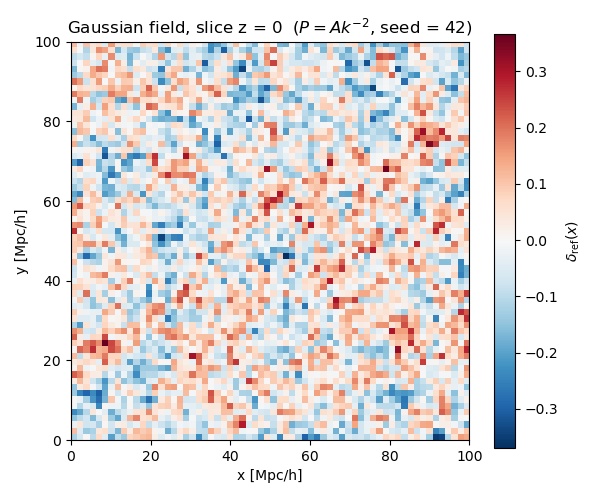

In [4]:
# Slice of the Gaussian field through z = 0
plt.close("all")
fig, ax = plt.subplots(figsize=(6, 5))

# Transpose so that x is horizontal and y vertical; origin at the bottom-left corner
im = ax.imshow(delta_x[:, :, 0].T, origin="lower", extent=[0, L, 0, L], cmap="RdBu_r")
fig.colorbar(im, ax=ax, label=r"$\delta_{\rm ref}(x)$")
ax.set_xlabel("x [Mpc/h]")
ax.set_ylabel("y [Mpc/h]")
ax.set_title(f"Gaussian field, slice z = 0  ($P = A k^{{{n:g}}}$, seed = {seed})")

plt.tight_layout()
plt.show()

**Spectrum of the drawn field.** No growth applied yet, so it must match $P_L(k, a_{\rm ref})$. Shell estimator (eq. 7.9): $\hat P(k) = \langle|\delta_k|^2\rangle_{\rm shell}/V$. The scatter at low $k$ is cosmic variance (few modes per shell).

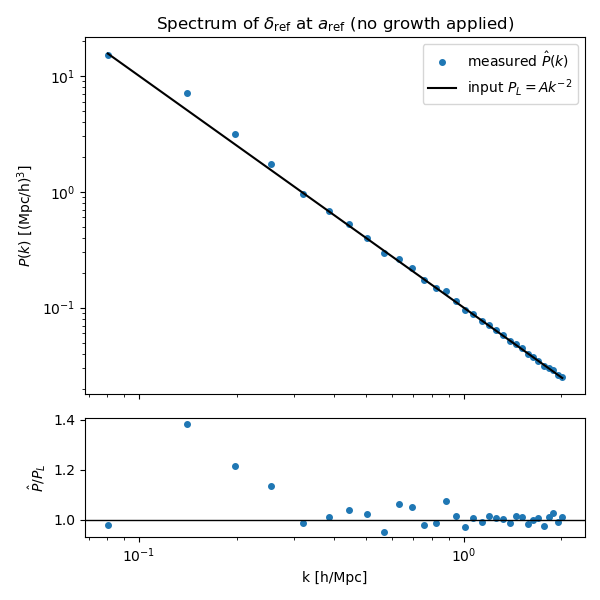

In [5]:
# Shell-averaged power spectrum of delta_ref,k, up to the 1D Nyquist wavenumber
nbins = Ng // 2       # shells of width k_f centred on k_f, 2 k_f, ..., k_Ny
k_bin, P_hat, n_modes = ex3.power_spectrum_from_k(delta_k, L, nbins)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6), sharex=True, height_ratios=[3, 1])

# Top: measured vs input spectrum
ax1.loglog(k_bin, P_hat, "o", ms=4, label=r"measured $\hat P(k)$")
ax1.loglog(k_bin, ex3.power_law_spectrum(k_bin, A, n), "k-", label=rf"input $P_L = A k^{{{n:g}}}$")
ax1.set_ylabel(r"$P(k)$ [(Mpc/h)$^3$]")
ax1.set_title(r"Spectrum of $\delta_{\rm ref}$ at $a_{\rm ref}$ (no growth applied)")
ax1.legend()

# Bottom: ratio measured / input (should scatter around 1)
ax2.semilogx(k_bin, P_hat / ex3.power_law_spectrum(k_bin, A, n), "o", ms=4)
ax2.axhline(1.0, color="k", lw=1)
ax2.set_xlabel("k [h/Mpc]")
ax2.set_ylabel(r"$\hat P / P_L$")

plt.tight_layout()
plt.show()

## (b) ZA positions and velocities

Growth applied **once**, inside $\Psi$, with $D_1(a_i)$, $f_1(a_i)$ from Exercise 1 (flat ΛCDM, $D_1(1) = 1$). Eqs. 7.25-7.27:
$$\Psi_k = i D_1(a_i)\,\frac{k_d}{k_d^2}\,\delta_{\rm ref,k}, \qquad x_p = (q_p + \Psi_p) \bmod L, \qquad v_p = \mathcal{H}_i f_{1,i}\,\Psi_p.$$

Lattice $q_j = (L/N_p)\,j$ with $N_p = N_g$: particles sit on the mesh nodes, so no interpolation of $\Psi$. Velocities in km/s ($v = a\,dx/dt$).

In [6]:
# Cosmology and start epoch
Om0, OL0 = 0.3, 0.7     # flat LCDM (Exercise 1)
H0 = 100.0              # Hubble constant [h km/s/Mpc], consistent with L in Mpc/h
z_i = 49.0              # start redshift
a_i = 1.0 / (1.0 + z_i)

# Growth factor and growth rate at a_i, normalized to D1(a_ref = 1) = 1
D1_i, f1_i = ex1.growth_ode(a_i, Om0, OL0)
D1_i, f1_i = D1_i[0], f1_i[0]           # growth_ode returns arrays

# Conformal Hubble rate calH = a H0 E(a)  [km/s per Mpc/h]
calH_i = a_i * H0 * np.sqrt(ex1.E2(a_i, Om0, OL0))

print(f"a_i = {a_i:.4f}:  D1 = {D1_i:.5f},  f1 = {f1_i:.5f},  calH = {calH_i:.2f} km/s/(Mpc/h)")

a_i = 0.0200:  D1 = 0.02567,  f1 = 0.99999,  calH = 387.30 km/s/(Mpc/h)


In [7]:
# ZA particles at a_i: labels q, positions x, velocities v, displacements Psi (each N_p^3 x 3)
q, x, v, Psi = ex3.za_particles(delta_k, L, D1_i, f1_i, calH_i)

# Displacement size relative to the mean particle spacing l_p = L / N_p (eq. 7.37):
# sigma_Psi / l_p << 1 means no shell crossing and ZA is well inside the linear regime
l_p = L / Ng
Psi_abs = np.sqrt(np.sum(Psi**2, axis=1))      # |Psi| of each particle
print(f"N_p^3 = {len(q)} particles,  l_p = {l_p:.4f} Mpc/h")
print(f"sigma_Psi / l_p = {Psi.std():.2e} / {l_p:.3f} = {Psi.std() / l_p:.2e}")
print(f"max|Psi| / l_p  = {Psi_abs.max() / l_p:.2e}")
print(f"rms velocity    = {np.sqrt(np.mean(np.sum(v**2, axis=1))):.2f} km/s")

N_p^3 = 262144 particles,  l_p = 1.5625 Mpc/h
sigma_Psi / l_p = 4.77e-03 / 1.562 = 3.05e-03
max|Psi| / l_p  = 1.43e-02
rms velocity    = 3.20 km/s


**Spectrum at $a_i$.** Gaussian field $D_1(a_i)\,\delta_{\rm ref}$ vs ZA particles assigned back to the mesh with CIC (Section 8.2), both against $D_1^2(a_i)\,P_L$. The CIC spectrum drops near $k_{\rm Ny}$ (mass assignment); this is treated in (d).

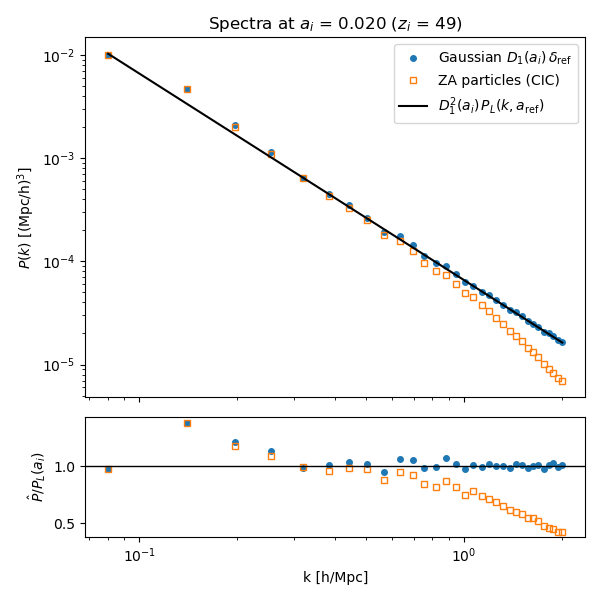

In [8]:
# Density of the ZA particles on the mesh (CIC): delta_j = rho_j / rho_mean - 1, then its Fourier coefficients
delta_za_x = ex3.cic_density(x, L, Ng)
delta_za_k = ex3.field_k(delta_za_x, L)

# Shell-averaged spectra at a_i: Gaussian field grown by D1(a_i), and ZA particles
k_bin, P_gauss_i, _ = ex3.power_spectrum_from_k(D1_i * delta_k, L, nbins)
k_bin, P_za_i, _ = ex3.power_spectrum_from_k(delta_za_k, L, nbins)
P_lin_i = D1_i**2 * ex3.power_law_spectrum(k_bin, A, n)     # P_L(k, a_i), eq. 7.4

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6), sharex=True, height_ratios=[3, 1])

# Top: spectra
ax1.loglog(k_bin, P_gauss_i, "o", ms=4, label=r"Gaussian $D_1(a_i)\,\delta_{\rm ref}$")
ax1.loglog(k_bin, P_za_i, "s", ms=4, mfc="none", label="ZA particles (CIC)")
ax1.loglog(k_bin, P_lin_i, "k-", label=r"$D_1^2(a_i)\,P_L(k, a_{\rm ref})$")
ax1.set_ylabel(r"$P(k)$ [(Mpc/h)$^3$]")
ax1.set_title(rf"Spectra at $a_i$ = {a_i:.3f} ($z_i$ = {z_i:g})")
ax1.legend()

# Bottom: ratios to the linear spectrum at a_i
ax2.semilogx(k_bin, P_gauss_i / P_lin_i, "o", ms=4)
ax2.semilogx(k_bin, P_za_i / P_lin_i, "s", ms=4, mfc="none")
ax2.axhline(1.0, color="k", lw=1)
ax2.set_xlabel("k [h/Mpc]")
ax2.set_ylabel(r"$\hat P / P_L(a_i)$")

plt.tight_layout()
plt.show()

## (c) Validate each step

Checks of Lecture 7, Section 8.1, on the arrays of (a)-(b), with the same discrete operators ($k_d$):

| Check | Requirement | Ref. |
|---|---|---|
| Mean density | $\langle\delta\rangle = 0$, $\delta_0 = 0$ | 8.2 |
| Hermitian symmetry | $\delta_{-k} = \delta_k^*$ | 8.1 |
| Imaginary FFT residual | round-off | 8.3 |
| Divergence | $-\nabla\cdot\Psi = D_1\delta_{\rm ref}$ | 8.5 |
| Curl | $\nabla\times\Psi = 0$ | 8.6 |
| Mean displacement | $\langle\Psi\rangle = 0$ | 8.7 |
| Particles | $x \in [0, L)$, mass conserved, no CM shift | 8.1.3 |
| Velocity | $v = \mathcal{H}_i f_{1,i}\Psi$ | 8.8 |

In [9]:
# --- Gaussian field: mean density, Hermitian symmetry, imaginary residual ---
print("Gaussian field")
print(f"  delta_0 = {delta_k[0, 0, 0]:.1e},  mean(delta) = {delta_x.mean():.1e}")
print(f"  Hermitian residual max|delta_k - conj(delta_-k)| / max|delta_k| = {ex3.hermitian_residual(delta_k):.1e}")

# Imaginary part of the raw inverse FFT, relative to the real part (should be round-off)
c_delta = np.fft.ifftn(delta_k)
print(f"  max|Im delta(x)| / max|Re delta(x)| = {np.abs(c_delta.imag).max() / np.abs(c_delta.real).max():.1e}")

# Same for the three displacement components built in (b)
Psi_k_b = ex3.displacement_k(delta_k, L, D1_i)
for name, P in zip("xyz", Psi_k_b):
    c_P = np.fft.ifftn(P)
    print(f"  max|Im Psi_{name}(x)| / max|Re Psi_{name}(x)| = {np.abs(c_P.imag).max() / np.abs(c_P.real).max():.1e}")

Gaussian field
  delta_0 = 0.0e+00+0.0e+00j,  mean(delta) = 5.0e-19
  Hermitian residual max|delta_k - conj(delta_-k)| / max|delta_k| = 0.0e+00
  max|Im delta(x)| / max|Re delta(x)| = 0.0e+00
  max|Im Psi_x(x)| / max|Re Psi_x(x)| = 0.0e+00
  max|Im Psi_y(x)| / max|Re Psi_y(x)| = 0.0e+00
  max|Im Psi_z(x)| / max|Re Psi_z(x)| = 0.0e+00


In [10]:
# --- Displacement: divergence, curl and mean ---
# Fourier coefficients of the REAL-SPACE displacement given to the particles,
# so the test covers the whole chain (Fourier -> real space -> Fourier)
Psi_k = [ex3.field_k(Psi[:, i].reshape(Ng, Ng, Ng), L) for i in range(3)]

# Divergence residual: -div Psi - D1 delta_ref (in Fourier space)
div_k = ex3.divergence_k(Psi_k, L)
res_k = -div_k - D1_i * delta_k

# Cells with k_d = 0 but k != 0 (all components 0 or Nyquist): Psi_k = 0 there by construction,
# so the residual there is D1 delta_ref itself. They are reported separately.
k_d = ex3.derivative_wavevectors(L, Ng)
kd2 = k_d[0]**2 + k_d[1]**2 + k_d[2]**2
pure_nyq = (kd2 == 0) & (k > 0)

scale = np.abs(D1_i * delta_k).max()     # normalization of the residual
print("Displacement")
print(f"  divergence: max|res_k| / max|D1 delta_k|, all other cells    = {np.abs(res_k[~pure_nyq]).max() / scale:.1e}")
print(f"  divergence: max|res_k| / max|D1 delta_k|, {pure_nyq.sum()} pure-Nyquist cells = {np.abs(res_k[pure_nyq]).max() / scale:.1e}")

# Same residual in real space, relative to the rms of D1 delta_ref
res_x = ex3.field_x(res_k, L)
print(f"  divergence: rms(res(x)) / rms(D1 delta(x)) = {res_x.std() / (D1_i * delta_x).std():.1e}")

# Curl, relative to the divergence (Psi must be a pure gradient)
curl = ex3.curl_k(Psi_k, L)
print(f"  curl: max|curl_k| / max|div_k| = {max(np.abs(c).max() for c in curl) / np.abs(div_k).max():.1e}")

# Mean displacement, relative to its rms
print(f"  mean(Psi) / sigma_Psi = {Psi.mean(axis=0) / Psi.std()}")

Displacement
  divergence: max|res_k| / max|D1 delta_k|, all other cells    = 1.5e-15
  divergence: max|res_k| / max|D1 delta_k|, 7 pure-Nyquist cells = 3.3e-02
  divergence: rms(res(x)) / rms(D1 delta(x)) = 2.4e-03
  curl: max|curl_k| / max|div_k| = 1.2e-15
  mean(Psi) / sigma_Psi = [ 1.27559097e-16 -1.16796989e-17 -4.14129943e-18]


In [11]:
# --- Particles: positions, total mass, centre of mass ---
print("Particles")
print(f"  min(x) = {x.min():.3e},  max(x) = {x.max():.6f}  (L = {L})")
print(f"  all positions in [0, L): {np.all((x >= 0) & (x < L))}")

# Total mass: unit-mass particles assigned with CIC; the mesh total must equal the particle number
rho = ex3.cic_mass(x, L, Ng)
print(f"  CIC total mass = {rho.sum():.6f},  number of particles = {len(x)}")

# Centre-of-mass shift modulo the box: minimum-image displacement x - q
# (maps x - q into [-L/2, L/2) so wrapped particles are not counted as a jump of L)
dx_min = (x - q + L / 2) % L - L / 2
print(f"  centre-of-mass shift = {dx_min.mean(axis=0)} Mpc/h")

Particles
  min(x) = 3.908e-08,  max(x) = 99.999999  (L = 100.0)
  all positions in [0, L): True
  CIC total mass = 262144.000000,  number of particles = 262144
  centre-of-mass shift = [-1.32272665e-17 -4.30970364e-18  4.20128342e-18] Mpc/h


**Velocity.** Check $v/\Psi = \mathcal{H}_i f_{1,i}$, and $f_1$ against a finite difference of $\ln D_1$ (independent test; at $z_i = 49$, $f_1 \approx 1$).

In [12]:
# --- Velocity normalization ---
# Ratio actually used: least-squares v . Psi / |Psi|^2 over all particles, should equal calH_i f1_i
ratio_v = np.sum(v * Psi) / np.sum(Psi**2)

# Independent f1: centred finite difference of ln D1 in N = ln a, with step h
h = 1e-3
D_plus, _ = ex1.growth_ode(a_i * np.exp(h), Om0, OL0)
D_minus, _ = ex1.growth_ode(a_i * np.exp(-h), Om0, OL0)
f1_fd = (np.log(D_plus[0]) - np.log(D_minus[0])) / (2 * h)

print("Velocity")
print(f"  v.Psi / |Psi|^2  = {ratio_v:.6f} km/s/(Mpc/h)")
print(f"  calH_i f1_i      = {calH_i * f1_i:.6f} km/s/(Mpc/h)")
print(f"  f1 (ODE) = {f1_i:.8f},  f1 (finite difference) = {f1_fd:.8f},  Omega_m(a_i) = {ex1.Omega_m(a_i, Om0, OL0):.6f}")

Velocity
  v.Psi / |Psi|^2  = 387.298006 km/s/(Mpc/h)
  calH_i f1_i      = 387.298006 km/s/(Mpc/h)
  f1 (ODE) = 0.99998982,  f1 (finite difference) = 0.99998982,  Omega_m(a_i) = 0.999981


## (d) Recover the spectrum

Estimator (eq. 8.4): $\hat P(k) = \frac{1}{N_k V}\sum_{k_a \in S_k}|\delta_{k_a}|^2$, shells of width $k_f$. Setup:
- **Assignment:** CIC, window $W(k) = \prod_i [\sin(k_i\Delta x/2)/(k_i\Delta x/2)]^2$ (eq. 8.10); shown raw and divided by $W$.
- **Load:** regular lattice, $N_p = N_g$, zero offset.
- **Shot noise:** a lattice is not Poisson, so $1/\bar n$ is **not** subtracted (Section 8.2).
- **Comparison:** ZA vs Gaussian with the same phases; the ratio cancels most cosmic variance (Section 8.3).

1/n_bar = 3.815 (Mpc/h)^3,  max P_L(k, a_i) on the mesh = 1.03e-02 (Mpc/h)^3


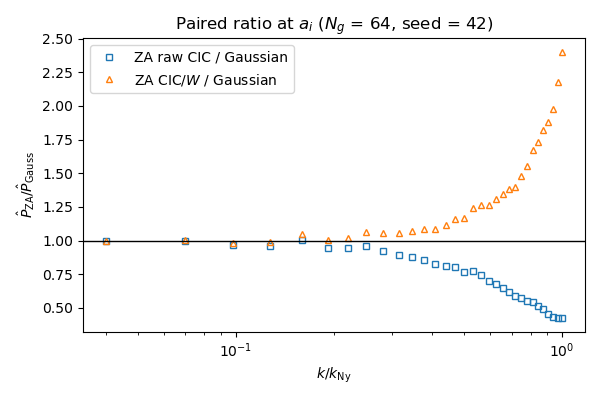

In [13]:
# Single realization (the one from (a)-(b)): raw and window-corrected ZA spectra
W_cic = ex3.cic_window(L, Ng)
k_bin, P_za_deconv_i, _ = ex3.power_spectrum_from_k(delta_za_k / W_cic, L, nbins)

# Shot-noise level that a Poisson sample would have (NOT subtracted, for reference only)
n_bar = len(x) / V
print(f"1/n_bar = {1 / n_bar:.3f} (Mpc/h)^3,  max P_L(k, a_i) on the mesh = {P_lin_i.max():.2e} (Mpc/h)^3")

# Paired ratio ZA / Gaussian (same phases), raw and divided by the CIC window
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogx(k_bin / k_Ny, P_za_i / P_gauss_i, "s", ms=4, mfc="none", label="ZA raw CIC / Gaussian")
ax.semilogx(k_bin / k_Ny, P_za_deconv_i / P_gauss_i, "^", ms=4, mfc="none", label=r"ZA CIC$/W$ / Gaussian")
ax.axhline(1.0, color="k", lw=1)
ax.set_xlabel(r"$k / k_{\rm Ny}$")
ax.set_ylabel(r"$\hat P_{\rm ZA} / \hat P_{\rm Gauss}$")
ax.set_title(f"Paired ratio at $a_i$ ($N_g$ = {Ng}, seed = {seed})")
ax.legend()
plt.tight_layout()
plt.show()

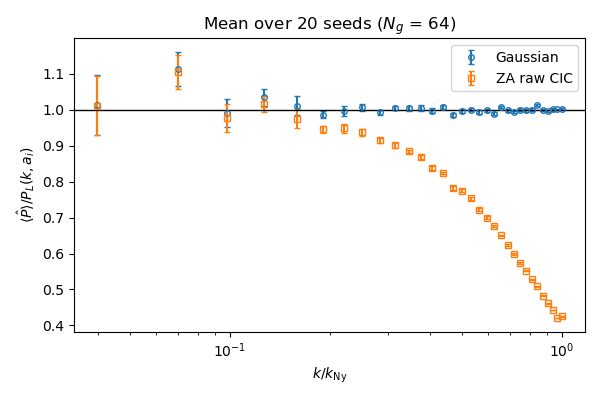

shell k/k_Ny   std(P_gauss/P_L)   std(P_ZA/P_gauss)
  0.040        0.369              0.0057
  0.070        0.215              0.0116
  0.098        0.171              0.0113
  0.127        0.103              0.0137


In [14]:
# Different seeds at fixed resolution: mean and scatter of the ratios to P_L(k, a_i)
seeds = np.arange(20)
ratio_gauss, ratio_za, ratio_pair = [], [], []
for s in seeds:
    # Full pipeline for one seed: Gaussian field, ZA particles, CIC, spectra
    k_s, Pg, Pz, Pz_dec = ex3.measure_spectra(L, Ng, A, n, s, D1_i, f1_i, calH_i, nbins)
    P_lin = D1_i**2 * ex3.power_law_spectrum(k_s, A, n)
    ratio_gauss.append(Pg / P_lin)     # Gaussian / linear theory
    ratio_za.append(Pz / P_lin)        # ZA (raw CIC) / linear theory
    ratio_pair.append(Pz / Pg)         # paired ratio, same phases
ratio_gauss, ratio_za, ratio_pair = map(np.array, (ratio_gauss, ratio_za, ratio_pair))

fig, ax = plt.subplots(figsize=(6, 4))
# Error bars: standard error of the mean over the seeds
for r, mk, lab in [(ratio_gauss, "o", "Gaussian"), (ratio_za, "s", "ZA raw CIC")]:
    ax.errorbar(k_s / k_Ny, r.mean(axis=0), yerr=r.std(axis=0) / np.sqrt(len(seeds)),
                fmt=mk, ms=4, mfc="none", capsize=2, label=lab)
ax.axhline(1.0, color="k", lw=1)
ax.set_xscale("log")
ax.set_xlabel(r"$k / k_{\rm Ny}$")
ax.set_ylabel(r"$\langle \hat P \rangle / P_L(k, a_i)$")
ax.set_title(f"Mean over {len(seeds)} seeds ($N_g$ = {Ng})")
ax.legend()
plt.tight_layout()
plt.show()

# Seed-to-seed scatter of the single and paired ratios in the first shells
print("shell k/k_Ny   std(P_gauss/P_L)   std(P_ZA/P_gauss)")
for i in range(4):
    print(f"  {k_s[i] / k_Ny:.3f}        {ratio_gauss[:, i].std():.3f}              {ratio_pair[:, i].std():.4f}")

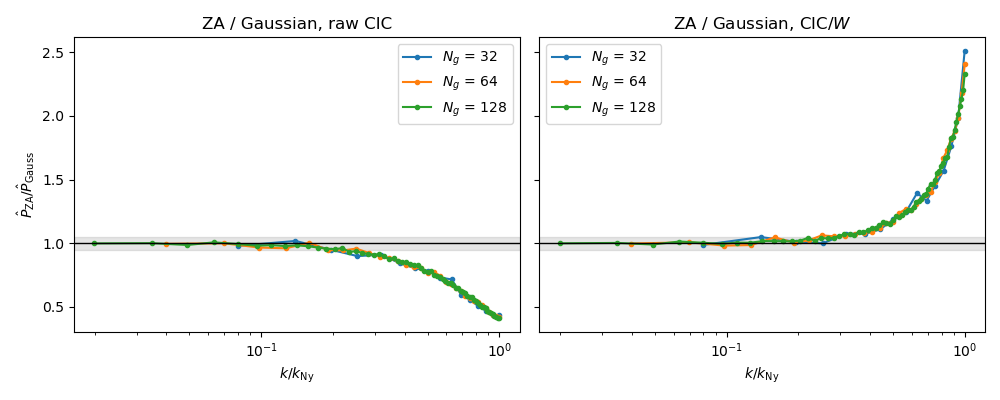

In [15]:
# Different resolutions at fixed box: paired ratio ZA / Gaussian versus k / k_Ny
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for Ng_r in (32, 64, 128):
    # Same seed, so the large-scale phases are the same at every resolution
    k_r, Pg, Pz, Pz_dec = ex3.measure_spectra(L, Ng_r, A, n, seed, D1_i, f1_i, calH_i, Ng_r // 2)
    k_Ny_r = np.pi * Ng_r / L
    ax1.semilogx(k_r / k_Ny_r, Pz / Pg, ".-", label=f"$N_g$ = {Ng_r}")       # raw CIC
    ax2.semilogx(k_r / k_Ny_r, Pz_dec / Pg, ".-", label=f"$N_g$ = {Ng_r}")   # CIC / W

for ax, title in [(ax1, "raw CIC"), (ax2, r"CIC$/W$")]:
    ax.axhline(1.0, color="k", lw=1)
    ax.axhspan(0.95, 1.05, color="gray", alpha=0.2)   # +-5% tolerance band
    ax.set_xlabel(r"$k / k_{\rm Ny}$")
    ax.set_title(f"ZA / Gaussian, {title}")
    ax.legend()
ax1.set_ylabel(r"$\hat P_{\rm ZA} / \hat P_{\rm Gauss}$")
plt.tight_layout()
plt.show()

**Summary of (d).**
- **Normalization:** over 20 seeds, $\hat P_{\rm Gauss}/P_L$ is consistent with 1; one realization scatters up to $\sim 37\%$ in the first shells.
- **Pairing:** $\hat P_{\rm ZA}/\hat P_{\rm Gauss}$ scatters by $\sim 1\%$ vs $10$–$37\%$ for $\hat P_{\rm Gauss}/P_L$.
- **Resolution:** $N_g = 32, 64, 128$ fall on one curve in $k/k_{\rm Ny}$ → the deviation comes from the mesh (assignment, aliasing), not from ZA ($\sigma_\Psi/l_p \sim 3\times10^{-3}$).
- **Window:** raw CIC is too low near $k_{\rm Ny}$; dividing by $W$ over-corrects (up to $\sim 2.5\times$), since aliasing is not removed.
- **Usable range** ($\pm5\%$): $k \lesssim 0.2$–$0.25\,k_{\rm Ny}$ raw, $\lesssim 0.28$–$0.32\,k_{\rm Ny}$ with $W$ divided out; for $N_g = 64$ this is $k \lesssim 0.5$ h/Mpc.
- **Shot noise:** $1/\bar n \approx 3.8$ (Mpc/h)³ is $> 300\times$ the largest $P_L(k, a_i)$; subtracting it would make $\hat P < 0$.